--- Analysis Results ---
Total Energy Sum: 128.54 MeV (Recovery: 64.3%)
Interaction Length (lambda): 84.66 cm
------------------------


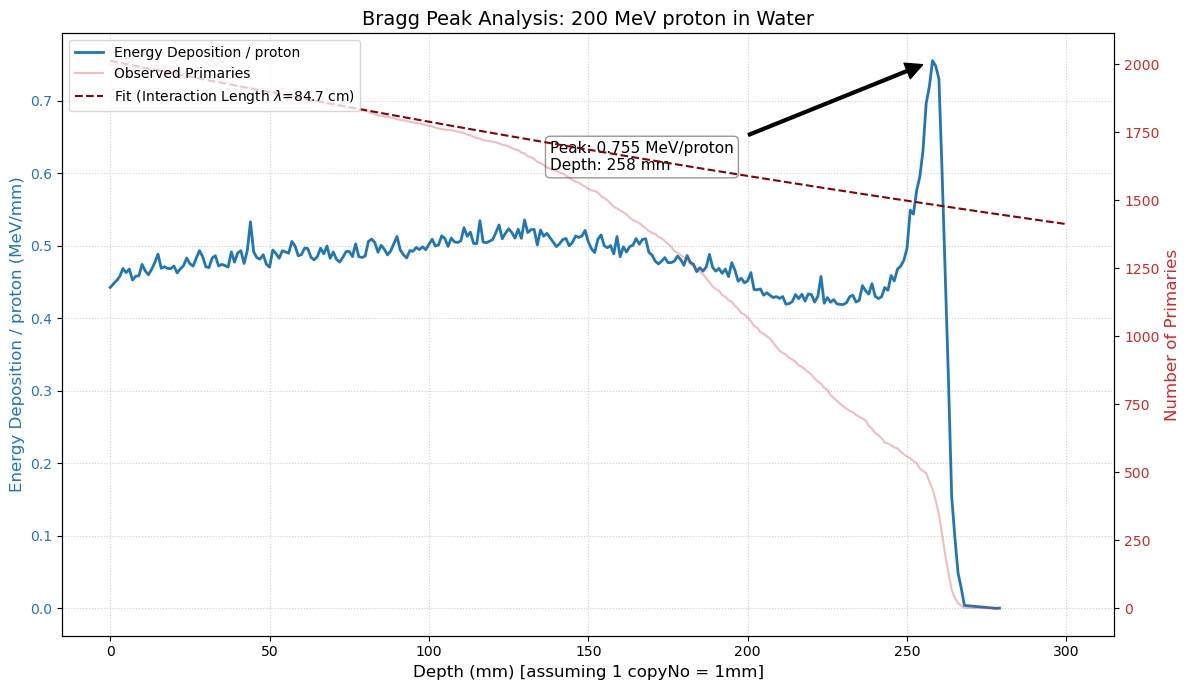

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. データの読み込みと正規化
df = pd.read_csv('protonEdep.csv')
df.columns = [c.strip() for c in df.columns]

beam_on = 2000
# Energy per proton (MeV/proton) への換算
df['energy_per_proton'] = df['energy'] / beam_on

# 2. ピークの特定
peak_idx = df['energy_per_proton'].idxmax()
peak_depth = df.loc[peak_idx, 'copyNo']
peak_val = df.loc[peak_idx, 'energy_per_proton']

# 3. エネルギーの合計値計算と200MeVとの比較
total_energy_sum = df['energy_per_proton'].sum()
incident_energy = 200.0
recovery_rate = (total_energy_sum / incident_energy) * 100

# 4. Interaction Length (λ) の解析
# 1 copyNo = 1 mm = 0.1 cm と仮定
def exp_decay(x, N0, lam):
    return N0 * np.exp(-x / lam)

# Bragg Peak の手前（指数関数的な減衰が見られる領域）でフィッティング
fit_range = df[df['copyNo'] < 80]
popt, _ = curve_fit(exp_decay, fit_range['copyNo'] * 0.1, fit_range['primaries'], p0=[2000, 70])
fitted_lam = popt[1]

# 5. 可視化
fig, ax1 = plt.subplots(figsize=(12, 7))

# エネルギー付与のプロット
color_energy = 'tab:blue'
ax1.set_xlabel('Depth (mm) [assuming 1 copyNo = 1mm]', fontsize=12)
ax1.set_ylabel('Energy Deposition / proton (MeV/mm)', color=color_energy, fontsize=12)
ax1.plot(df['copyNo'], df['energy_per_proton'], color=color_energy, label='Energy Deposition / proton', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_energy)

# ピークの注釈
ax1.annotate(f'Peak: {peak_val:.3f} MeV/proton\nDepth: {peak_depth} mm',
             xy=(peak_depth, peak_val), xytext=(peak_depth-120, peak_val*0.8),
             arrowprops=dict(facecolor='black', shrink=0.05, width=2),
             fontsize=11, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

# Primary 数のプロット
ax2 = ax1.twinx()
color_prim = 'tab:red'
ax2.set_ylabel('Number of Primaries', color=color_prim, fontsize=12)
ax2.plot(df['copyNo'], df['primaries'], color=color_prim, alpha=0.3, label='Observed Primaries')
ax2.tick_params(axis='y', labelcolor=color_prim)

# フィッティング曲線の描画
x_fit = np.linspace(0, 300, 100)
y_fit = exp_decay(x_fit * 0.1, *popt)
ax2.plot(x_fit, y_fit, color='darkred', linestyle='--', label=rf'Fit (Interaction Length $\lambda$={fitted_lam:.1f} cm)')

# 凡例とタイトルの設定
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Bragg Peak Analysis: 200 MeV proton in Water', fontsize=14)
ax1.grid(True, linestyle=':', alpha=0.6)

# 数値結果の出力
print(f"--- Analysis Results ---")
print(f"Total Energy Sum: {total_energy_sum:.2f} MeV (Recovery: {recovery_rate:.1f}%)")
print(f"Interaction Length (lambda): {fitted_lam:.2f} cm")
print(f"------------------------")

plt.tight_layout()
plt.show()